# Регрессия, ранжирование и Content ALS


## Данные: покупки и корзины в T‑ECD

Используем Retail из [T‑ECD от Т‑Банка](https://huggingface.co/datasets/t-tech/T-ECD):
добавления в корзину, заказы и готовые 300-мерные векторы товаров.
У товаров есть категории и подкатегории; названия анонимизированы.


Файл [tecd_retail_ready.npz](https://drive.google.com/file/d/1Ic9514FG3uOipsbNfTlY0-5Td5hlIllT/view?usp=drivesdk) лежит рядом с ноутбуком. В нём готовая
выборка: 14 543 пользователя, 10 000 товаров, пары корзин и заказов по периодам,
категории, исходные 300-мерные эмбеддинги и готовые 128-мерные векторы.
Для основных сравнений PCA и нормирование выполнены заранее.
Отдельно разберём PCA на небольшой матрице исходных эмбеддингов.

В Colab ячейка загрузит файл с Google Диска: при первом запуске
выберите Google-аккаунт с доступом к нему. Если файл уже загружен в панель
**«Файлы»**, повторное скачивание не требуется.
Локально оставьте его в одной папке с ноутбуком.

В обучении корзина или заказ означают положительное взаимодействие.
Цель проверки — **заказ в следующем периоде**. Повторные покупки допустимы:
ранее купленные товары остаются в каталоге рекомендаций.

Для занятия выбрали 10 000 товаров из полного Retail, чтобы обучение и
проверка работали быстрее. Таблица ниже показывает, какая доля будущих покупок
выбранных пользователей относится к этим товарам. Один товар учитывается
отдельно для каждого пользователя; повторные заказы того же товара одним
пользователем в одном периоде считаются один раз.

Пользователи и каталог выбраны только по обучающему периоду. Между историей
и следующим периодом оставлен разрыв не менее 12 часов, как рекомендуют авторы
датасета из-за шума во времени событий. Проверяем весь выбранный каталог,
а не только товары, которые пользователь купил в будущем.

Источник: Liakhnovich et al., *T-ECD* (KDD 2026),
[статья](https://doi.org/10.1145/3770855.3817588).


In [7]:
from pathlib import Path
from time import perf_counter
import importlib.util
import json
import subprocess
import sys

if importlib.util.find_spec("implicit") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "implicit==0.7.3"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.special import expit
from implicit.cpu.als import AlternatingLeastSquares
from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=1)
SEED, K, FACTORS = 42, 10, 128
MF_EPOCHS = 100
CHECKPOINTS = (1, 4, 8, 12, 20, 40, 70, 100)
ALS_EPOCHS = 25
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.2})


In [8]:
data_path = Path("tecd_retail_ready.npz")
if not data_path.exists():
    try:
        from google.colab import auth
    except ImportError:
        raise FileNotFoundError("Положите tecd_retail_ready.npz рядом с ноутбуком.") from None

    import io
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload

    print("Загружаем данные с Google Диска. Выберите аккаунт с доступом к файлу.")
    auth.authenticate_user()
    drive_api = build("drive", "v3", cache_discovery=False)
    request = drive_api.files().get_media(fileId="1Ic9514FG3uOipsbNfTlY0-5Td5hlIllT")
    buffer = io.BytesIO()
    download = MediaIoBaseDownload(buffer, request)
    done = False
    while not done:
        _, done = download.next_chunk()
    data_path.write_bytes(buffer.getvalue())
data = np.load(data_path, allow_pickle=False)
assert "source_embeddings" in data, "Скачайте обновлённый tecd_retail_ready.npz с исходными эмбеддингами"
data_manifest = json.loads(data["manifest"].item())
E = np.ascontiguousarray(data["item_vectors"], dtype=np.float32)
assert E.shape[1] == FACTORS, "Нужен файл данных с 128-мерными векторами"
print(f"Данные загружены: {len(data['user_ids']):,} пользователей, {len(E):,} товаров.")


Загружаем данные с Google Диска. Выберите аккаунт с доступом к файлу.


Данные загружены: 14,543 пользователей, 10,000 товаров.


In [9]:
N_USERS, N_ITEMS = len(data["user_ids"]), len(data["item_ids"])

def interactions(prefix):
    matrix = sparse.csr_matrix(
        (np.ones(len(data[prefix + "_u"]), dtype=np.float32),
         (data[prefix + "_u"], data[prefix + "_i"])), shape=(N_USERS, N_ITEMS))
    matrix.sort_indices()
    return matrix

train, valid, test = [interactions(name) for name in ["train", "valid", "test"]]
valid_users = np.flatnonzero(np.diff(valid.indptr))
test_users = np.flatnonzero(np.diff(test.indptr))

pd.DataFrame([
    {"Период": "Обучение", "Дни": "1260–1277.5", "Пар": train.nnz,
     "Пользователей": np.count_nonzero(np.diff(train.indptr))},
    {"Период": "Валидация", "Дни": "1278–1282.5", "Пар": valid.nnz,
     "Пользователей": len(valid_users)},
    {"Период": "Тест", "Дни": "1283–1288", "Пар": test.nnz,
     "Пользователей": len(test_users)},
])


,Период,Дни,Пар,Пользователей
0,Обучение,1260–1277.5,355586,14543
1,Валидация,1278–1282.5,40149,3661
2,Тест,1283–1288,44461,3682


In [10]:
catalog = pd.DataFrame({"Товар": data["item_ids"], "Категория": data["category"],
                        "Подкатегория": data["subcategory"]})
display(catalog["Категория"].value_counts().head(8).rename("Товаров").to_frame())
pd.DataFrame(data_manifest["coverage"]).T.rename(columns={
    "users_with_targets": "Пользователей с заказами",
    "target_pairs_before_catalog_filter": "Заказанные товары — всего",
    "target_pairs_in_catalog": "Заказанные товары — из нашего каталога", "catalog_coverage": "Доля покупок, покрытая нашим каталогом"})


,Товаров
Категория,
Foodstuffs and Beverages,8647
"Cosmetics, Personal Care, and Health Maintenance Products",382
Unknown,245
Cleaning Supplies and Everyday Household Items,204
"Pet Supplies: Food, Accessories, and Grooming Products",200
Children's Products and Childcare Items,187
Home Improvement and Countryside Retreat Essentials,61
Other,42


,Заказанные товары — всего,Заказанные товары — из нашего каталога,"Доля покупок, покрытая нашим каталогом",Пользователей с заказами
valid,59369.0,40149.0,0.676262,3661.0
test,66314.0,44461.0,0.670462,3682.0


## Ошибка предсказания и порядок товаров

У пользователя есть два подходящих и два неподходящих товара.
Сравним предсказания: что лучше приближает значения, а что лучше сортирует товары?

$$\mathrm{MSE}=\frac1n\sum_i(t_i-s_i)^2,\qquad
\mathrm{DCG@K}=\sum_{r=1}^K\frac{t_{\pi(r)}}{\log_2(r+1)}.$$

Для двоичных целей NDCG — это DCG, делённый на DCG идеального порядка.


In [11]:
truth = np.array([1, 1, 0, 0])
predictions = {
    "A: значения близки, порядок ошибочен": np.array([0.49, 0.49, 0.51, 0.51]),
    "B: значения далеки, порядок верен": np.array([2.0, 1.9, 0.9, 0.8]),
}
discount = 1 / np.log2(np.arange(2, 4))
rows = []
for name, score in predictions.items():
    order = np.argsort(-score, kind="stable")
    rows.append({"Модель": name, "MSE": np.mean((truth - score) ** 2),
                 "NDCG@2": (truth[order[:2]] * discount).sum() / discount.sum(),
                 "Порядок товаров": order.tolist()})
pd.DataFrame(rows)


,Модель,MSE,NDCG@2,Порядок товаров
0,"A: значения близки, порядок ошибочен",0.2601,0.0,"[2, 3, 0, 1]"
1,"B: значения далеки, порядок верен",0.8150,1.0,"[0, 1, 2, 3]"


Теперь прибавим ко всем оценкам одно число. MSE изменится,
но разности $s(u,i)-s(u,j)$ и порядок товаров останутся прежними.


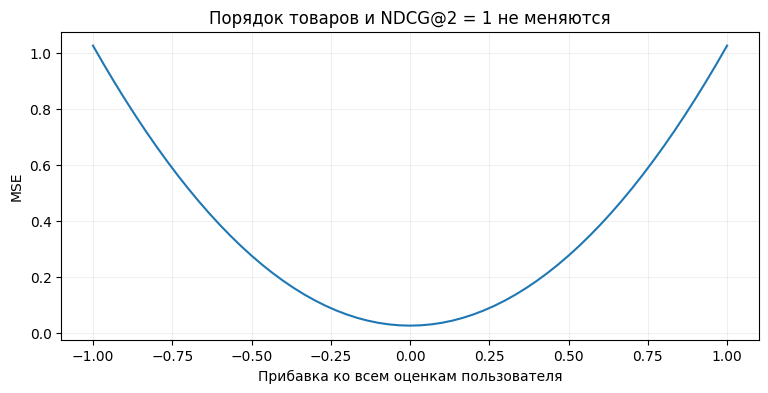

In [12]:
base_score = np.array([0.9, 0.8, 0.2, 0.1])
offsets = np.linspace(-1, 1, 61)
errors = [np.mean((truth - (base_score + offset)) ** 2) for offset in offsets]
fig, ax = plt.subplots()
ax.plot(offsets, errors)
ax.set(xlabel="Прибавка ко всем оценкам пользователя", ylabel="MSE",
       title="Порядок товаров и NDCG@2 = 1 не меняются")
plt.show()


## Матричная факторизация: MSE и BPR

Модель одна: $s(u,i)=x_u^\top y_i$. Меняем только функцию потерь.
Тройка $(u,i,j)$ содержит пользователя, товар из его истории и товар без
обучающего взаимодействия.

MSE приближает значения 1 и 0:

$$\ell_{\mathrm{MSE}}=\tfrac12[(s(u,i)-1)^2+s(u,j)^2].$$

BPR увеличивает разность оценок:

$$\ell_{\mathrm{BPR}}=\log(1+\exp(s(u,j)-s(u,i))).$$

К лоссу каждой тройки добавляем
$\frac\lambda2(\|x_u\|^2+\|y_i\|^2+\|y_j\|^2)$.
Инициализация, размерность, тройки и число обновлений в каждой контрольной
точке одинаковы. BPR оптимизирует порядок пар, но не NDCG напрямую.


In [13]:
train_u, train_i = train.nonzero()
pair_keys = np.sort(train_u.astype(np.int64) * N_ITEMS + train_i)

def draw_negatives(users, rng, known_pairs=pair_keys):
    # Запрещаем только известную обучающую историю. Будущее здесь не читаем.
    negative = rng.integers(N_ITEMS, size=len(users))
    collision = np.isin(users.astype(np.int64) * N_ITEMS + negative, known_pairs)
    while collision.any():
        negative[collision] = rng.integers(N_ITEMS, size=collision.sum())
        collision = np.isin(users.astype(np.int64) * N_ITEMS + negative, known_pairs)
    return negative

rng = np.random.default_rng(SEED)
train_j = draw_negatives(train_u, rng)
assert not np.isin(train_u.astype(np.int64) * N_ITEMS + train_j, pair_keys).any()


### Градиенты

Обозначим производные по двум оценкам через $g_i$ и $g_j$.

| Потеря | $g_i$ | $g_j$ |
|---|---|---|
| MSE | $s(u,i)-1$ | $s(u,j)$ |
| BPR | $-\sigma(s(u,j)-s(u,i))$ | $\sigma(s(u,j)-s(u,i))$ |

Дальше цепное правило:

$$\nabla_{x_u}\ell=g_i y_i+g_j y_j,\quad
\nabla_{y_i}\ell=g_i x_u,\quad \nabla_{y_j}\ell=g_j x_u.$$

`np.add.at` складывает обновления повторных индексов внутри пакета.
Обычное `X[u] -= ...` часть таких обновлений потеряет.


In [14]:
def mf_epoch(X, Y, users, positive, negative, order, loss, lr=0.04, reg=0.03):
    losses = []
    for start in range(0, len(order), 1024):
        batch = order[start:start + 1024]
        u, i, j = users[batch], positive[batch], negative[batch]
        x, yi, yj = X[u].copy(), Y[i].copy(), Y[j].copy()
        si, sj = np.sum(x * yi, axis=1), np.sum(x * yj, axis=1)
        if loss == "MSE":
            gi, gj = si - 1, sj
            batch_loss = 0.5 * ((si - 1) ** 2 + sj ** 2)
        else:
            gj = expit(sj - si)
            gi = -gj
            batch_loss = np.logaddexp(0, sj - si)
        np.add.at(X, u, -lr * (gi[:, None] * yi + gj[:, None] * yj + reg * x))
        np.add.at(Y, i, -lr * (gi[:, None] * x + reg * yi))
        np.add.at(Y, j, -lr * (gj[:, None] * x + reg * yj))
        losses.append(batch_loss.sum())
    return sum(losses) / len(order)


### Проверка рекомендаций

Считаем NDCG@10, Recall@10 и долю пользователей хотя бы с одним попаданием.
Последняя величина в таблицах дана в процентах. При равных оценках первым
идёт товар с меньшим индексом. Функция оценки ниже используется во всех сравнениях.


In [15]:
def ranking_metrics(score_function, targets, users, candidates=None):
    rows = []
    for start in range(0, len(users), 192):
        batch = users[start:start + 192]
        scores = score_function(batch)
        if candidates is None:
            relevance = targets[batch].toarray()
        else:
            pool = candidates[start:start + len(batch)]
            scores = np.take_along_axis(scores, pool, axis=1)
            relevance = np.take_along_axis(targets[batch].toarray(), pool, axis=1)
        top = np.argsort(-scores, axis=1, kind="stable")[:, :K]
        hits = np.take_along_axis(relevance, top, axis=1)
        count = np.asarray(targets[batch].sum(axis=1)).ravel()
        assert np.all(count > 0), "Для метрик нужны пользователи с ненулевыми целями"
        discount = 1 / np.log2(np.arange(2, K + 2))
        ideal = np.cumsum(discount)[np.minimum(count.astype(int), K) - 1]
        rows.append(np.column_stack(((hits * discount).sum(axis=1) / ideal,
                                     hits.sum(axis=1) / count, hits.any(axis=1))))
    return np.vstack(rows)

def metric_row(name, values):
    ndcg, recall, hit = values.mean(axis=0)
    return {"Модель": name, "NDCG@10": ndcg, "Recall@10": recall,
            "Пользователей с попаданием, %": 100 * hit, "Пользователей": len(values)}

def factor_scores(X, Y):
    return lambda users: X[users] @ Y.T

popularity = np.asarray(train.sum(axis=0)).ravel()
pop_values = ranking_metrics(lambda users: np.broadcast_to(popularity, (len(users), N_ITEMS)),
                             valid, valid_users)


### Обучение

Ненаблюдаемые товары выбираем заново на каждой эпохе; для обеих моделей
выборки совпадают. Обучаем по 100 эпох и проверяем эпохи 1, 4, 8, 12, 20, 40, 70 и 100.
Для теста сохраняем модель с лучшим NDCG на валидации.

Слева — собственная функция потерь каждой модели, справа — NDCG на будущем.
Абсолютные значения MSE и BPR между собой не сравниваем.


In [ ]:
initial_rng = np.random.default_rng(SEED)
initial_X = initial_rng.normal(0, 0.1, (N_USERS, FACTORS)).astype(np.float32)
initial_Y = initial_rng.normal(0, 0.1, (N_ITEMS, FACTORS)).astype(np.float32)
mf_models, learning_rows, mf_values, selected_epochs = {}, [], {}, {}

for loss in ["MSE", "BPR"]:
    X, Y = initial_X.copy(), initial_Y.copy()
    order_rng = np.random.default_rng(SEED)
    negative_rng = np.random.default_rng(SEED + 2)
    best_ndcg = -np.inf
    started = perf_counter()
    for epoch in range(1, MF_EPOCHS + 1):
        negative = draw_negatives(train_u, negative_rng)
        value = mf_epoch(X, Y, train_u, train_i, negative,
                         order_rng.permutation(len(train_u)), loss)
        assert np.isfinite(X).all() and np.isfinite(Y).all()
        if epoch in CHECKPOINTS:
            scores = ranking_metrics(factor_scores(X, Y), valid, valid_users)
            learning_rows.append({"Модель": loss, "Эпоха": epoch,
                                  "Обучающая потеря": value, "NDCG@10": scores[:, 0].mean()})
            print(f"{loss}: эпоха {epoch}/{MF_EPOCHS}, NDCG@10 = {scores[:, 0].mean():.4f}")
            if scores[:, 0].mean() > best_ndcg:
                best_ndcg = scores[:, 0].mean()
                mf_models[loss] = (X.copy(), Y.copy())
                mf_values[loss] = scores.copy()
                selected_epochs[loss] = epoch
    print(f"{loss}: {perf_counter() - started:.1f} с")

learning = pd.DataFrame(learning_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for loss, frame in learning.groupby("Модель", sort=False):
    axes[0].plot(frame["Эпоха"], frame["Обучающая потеря"], marker="o", label=loss)
    axes[1].plot(frame["Эпоха"], frame["NDCG@10"], marker="o", label=loss)
axes[0].set(xlabel="Эпоха", ylabel="Собственная функция потерь на обучении")
axes[1].set(xlabel="Эпоха", ylabel="NDCG@10 на валидации")
for ax in axes:
    ax.legend()
plt.show()
print("Выбранные по валидации эпохи:", selected_epochs)
pd.DataFrame([metric_row("Популярность", pop_values)] +
             [metric_row(name, values) for name, values in mf_values.items()])


MSE: эпоха 1/100, NDCG@10 = 0.0229
MSE: эпоха 4/100, NDCG@10 = 0.1495
MSE: эпоха 8/100, NDCG@10 = 0.1439
MSE: эпоха 12/100, NDCG@10 = 0.1179
MSE: эпоха 20/100, NDCG@10 = 0.1120
MSE: эпоха 40/100, NDCG@10 = 0.1320
MSE: эпоха 70/100, NDCG@10 = 0.1380


Посчитаем разницу NDCG по каждому пользователю и интервал среднего различия
повторной выборкой пользователей. Этот интервал относится к выбранному периоду
и запуску обучения.


In [ ]:
differences = mf_values["BPR"][:, 0] - mf_values["MSE"][:, 0]
bootstrap_rng = np.random.default_rng(SEED)
boot = [bootstrap_rng.choice(differences, len(differences), replace=True).mean()
        for _ in range(1000)]
pd.Series({"Средняя разница NDCG: BPR − MSE": differences.mean(),
           "Нижняя граница 95% интервала": np.quantile(boot, 0.025),
           "Верхняя граница 95% интервала": np.quantile(boot, 0.975)})


Средняя разница NDCG: BPR − MSE    0.072658
Нижняя граница 95% интервала       0.068254
Верхняя граница 95% интервала      0.076900
dtype: float64

### Полный каталог и случайные кандидаты

Не меняя модели, оставим все будущие цели пользователя и случайные товары
до общего размера 200. Сравним результат с каталогом из 10 000 товаров.
Этот сокращённый набор содержит ответы; он показывает эффект облегчённой
оценки, а не работу реального отбора кандидатов.


In [ ]:
candidate_rng = np.random.default_rng(SEED)
small_pools = []
for u in valid_users:
    positives = valid[u].indices
    others = np.setdiff1d(np.arange(N_ITEMS), positives)
    size = max(200, len(positives))
    extra = candidate_rng.choice(others, size=size - len(positives), replace=False)
    # Все пользователи должны иметь одинаковую ширину массива для пакетной оценки.
    small_pools.append(np.sort(np.r_[positives, extra]))
pool_width = max(map(len, small_pools))
if pool_width > 200:
    # В этой выборке максимум целей может быть больше 200: используем общую ширину.
    small_pools = [np.sort(np.r_[valid[u].indices,
        candidate_rng.choice(np.setdiff1d(np.arange(N_ITEMS), valid[u].indices),
                             pool_width - valid[u].nnz, replace=False)]) for u in valid_users]
small_pools = np.asarray(small_pools)
pool_rows = []
for name, (X, Y) in mf_models.items():
    reduced = ranking_metrics(factor_scores(X, Y), valid, valid_users, small_pools)
    pool_rows.append({"Модель": name, "NDCG@10, полный каталог": mf_values[name][:, 0].mean(),
                      "NDCG@10, сокращённый набор": reduced[:, 0].mean(),
                      "Товаров в сокращённом наборе": pool_width})
pd.DataFrame(pool_rows)


,Модель,"NDCG@10, полный каталог","NDCG@10, сокращённый набор",Товаров в сокращённом наборе
0,MSE,0.149524,0.517747,200
1,BPR,0.222183,0.529338,200


## Все ли координаты эмбеддинга нужны?

> У каждого товара вектор из 300 чисел. Как понять, что все эти координаты
> полезны? Можно ли оставить только часть и сохранить качество рекомендаций?

У исходных координат не задан порядок важности. При повороте векторов
скалярные произведения сохраняются, а значения отдельных координат меняются:

$$\langle e_iQ,e_jQ\rangle=\langle e_i,e_j\rangle,\qquad QQ^\top=I.$$

PCA выбирает новый базис: первое направление имеет наибольшую дисперсию,
каждое следующее — наибольшую среди направлений, ортогональных предыдущим.
Это важность для **восстановления векторов**, а не автоматически для рекомендаций.


### PCA через SVD

Нормируем исходные векторы и вычитаем среднее по товарам:

$$Z=E_{\mathrm{source}}-\mu=U\Sigma V^\top,\qquad Z_d=ZV_d.$$

Столбцы $V_d$ — первые $d$ главных направлений. Их дисперсии пропорциональны
$\sigma_j^2$, поэтому доля сохранённой дисперсии равна

$$R(d)=\frac{\sum_{j=1}^d\sigma_j^2}{\sum_{j=1}^{300}\sigma_j^2}.$$

Здесь SVD применяется к центрированной матрице — так получаем PCA.
Вычисление идёт только по фиксированному каталогу, без будущих заказов.


In [ ]:
source_vectors = data["source_embeddings"].astype(np.float32)
source_vectors /= np.linalg.norm(source_vectors, axis=1, keepdims=True)
mean_vector = source_vectors.mean(axis=0)
centered_vectors = source_vectors - mean_vector

_, singular_values, directions = np.linalg.svd(centered_vectors, full_matrices=False)
pca_coordinates = centered_vectors @ directions.T
variance_share = singular_values ** 2 / np.sum(singular_values ** 2)
cumulative_variance = np.cumsum(variance_share)


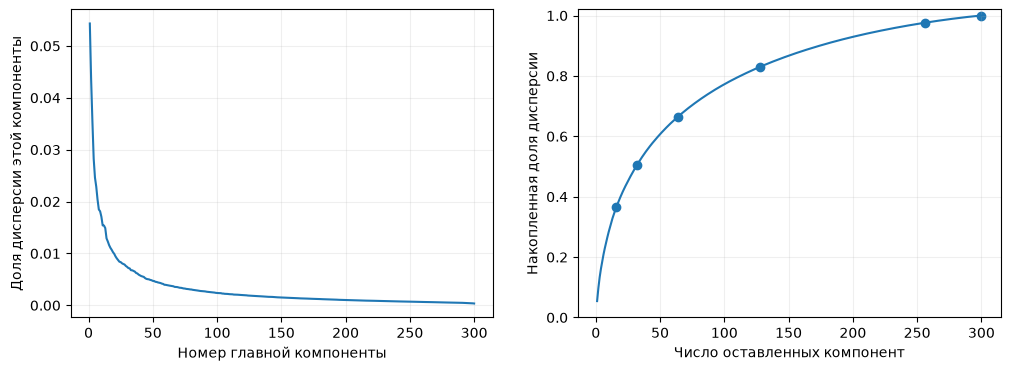

,Компонент,Доля сохранённой дисперсии
0,16,0.365709
1,32,0.504842
2,64,0.665339
3,128,0.830528
4,256,0.976149
5,300,1.000000


In [ ]:
dimensions = [16, 32, 64, 128, 256, 300]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, 301), variance_share)
axes[0].set(xlabel="Номер главной компоненты", ylabel="Доля дисперсии этой компоненты")
axes[1].plot(np.arange(1, 301), cumulative_variance)
axes[1].scatter(dimensions, cumulative_variance[np.array(dimensions) - 1])
axes[1].set(xlabel="Число оставленных компонент", ylabel="Накопленная доля дисперсии",
            ylim=(0, 1.02))
plt.show()

pd.DataFrame({"Компонент": dimensions,
              "Доля сохранённой дисперсии": cumulative_variance[np.array(dimensions) - 1]})


График показывает, какая доля вариативности векторов сохраняется при сжатии.
Это описание структуры эмбеддингов: дисперсия не измеряет всю информацию,
которая в них хранится, и не раскрывает смысл отдельных направлений.
Чтобы проверить пользу для рекомендаций, дальше обучим пользовательские векторы
при разных размерностях и сравним NDCG на одних и тех же будущих заказах.


## Content ALS

Товарный вектор $e_i$ уже известен и дальше не меняется.
Пользовательский вектор $x_u$ инициализируем случайно и обучаем по истории.
Ни общей проекции, ни индивидуальных поправок товаров здесь нет.


In [ ]:
print(f"Матрица товарных векторов: {E.shape[0]:,} × {E.shape[1]}")
E[:3, :5]


Матрица товарных векторов: 10,000 × 128


array([[ 0.12319985,  0.00215167, -0.1145376 , -0.25308713,  0.03932806],
       [-0.15630332, -0.28679112, -0.41028982,  0.01177177,  0.05943055],
       [-0.15454026,  0.29816794,  0.03396793,  0.16227281, -0.19410251]],
      dtype=float32)

### Обновление вектора пользователя

Для товаров из истории $p_{ui}=1$, $c_{ui}=20$; для остальных
$p_{ui}=0$, $c_{ui}=1$.

$$L_u(x)=\tfrac12\sum_i c_{ui}(p_{ui}-x^\top e_i)^2
          +\tfrac\lambda2\|x\|^2.$$

Обозначим историю через $H_u$:

$$A_u=E^\top E+\sum_{i\in H_u}(c_{ui}-1)e_ie_i^\top+\lambda I,
\qquad b_u=\sum_{i\in H_u}c_{ui}e_i.$$

$$\nabla L_u=A_ux-b_u,\qquad
x^{(t+1)}=x^{(t)}-\eta(A_ux^{(t)}-b_u).$$

Можно сделать несколько таких шагов или сразу решить систему:
$x^*=\operatorname{solve}(A_u,b_u)$. При $\lambda>0$ точное решение единственно
и не зависит от начального вектора.


In [ ]:
CONFIDENCE, REGULARIZATION = 20.0, 1.0

def user_system(history, item_vectors, confidence=CONFIDENCE, reg=REGULARIZATION):
    liked = item_vectors[history]
    A = item_vectors.T @ item_vectors + (confidence - 1) * (liked.T @ liked)
    A = A + reg * np.eye(item_vectors.shape[1])
    b = confidence * liked.sum(axis=0)
    return A, b

# Выбираем пользователя по длине обучающей истории
history_lengths = np.diff(train.indptr)
demo_user = int(np.argsort(history_lengths, kind="stable")[3 * N_USERS // 4])
history = train[demo_user].indices
A, b = user_system(history, E)
exact_user = np.linalg.solve(A, b)
print(f"Пользователь {demo_user}: {len(history)} товаров в обучающей истории")


Пользователь 3504: 31 товаров в обучающей истории


Начнём со случайного вектора. Для этого пользователя возьмём устойчивый
шаг $\eta=1/\lambda_{\max}(A_u)$.

Слева показываем превышение потерь над минимумом, справа — относительное
расстояние до точного решения. В таблице — как меняются первые рекомендации.


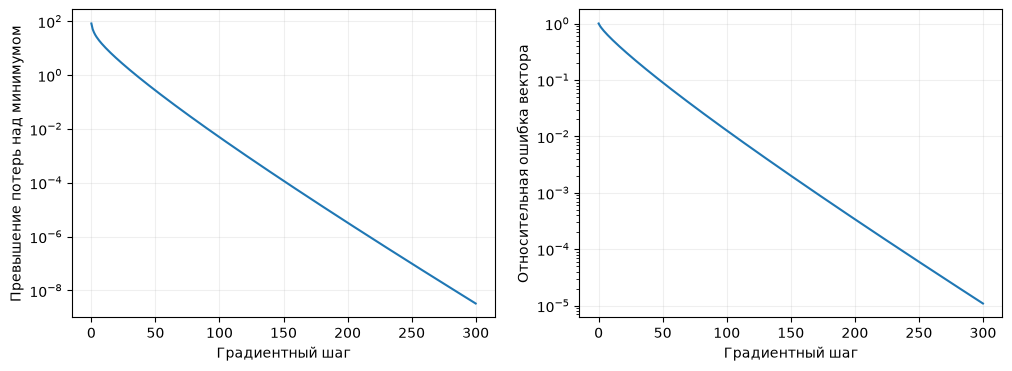

,Шаг,Первые 5 товаров,Подкатегории
0,0,"fmcg_1118607, fmcg_475562, fmcg_562613, fmcg_2...",Sweet Desserts and Confectionery; Fresh Vegeta...
1,1,"fmcg_1087432, fmcg_499011, fmcg_596639, fmcg_7...","Fresh Vegetables, Fruits, and Greens; Fresh Ve..."
2,5,"fmcg_1087432, fmcg_499011, fmcg_596639, fmcg_7...","Fresh Vegetables, Fruits, and Greens; Fresh Ve..."
3,30,"fmcg_133028, fmcg_334073, fmcg_536167, fmcg_73...","Fresh Vegetables, Fruits, and Greens; Fresh Ve..."
4,100,"fmcg_133028, fmcg_334073, fmcg_536167, fmcg_73...","Fresh Vegetables, Fruits, and Greens; Fresh Ve..."
5,300,"fmcg_133028, fmcg_334073, fmcg_536167, fmcg_73...","Fresh Vegetables, Fruits, and Greens; Fresh Ve..."


In [ ]:
x = np.random.default_rng(SEED).normal(0, 0.01, FACTORS)
learning_rate = 1 / np.linalg.eigvalsh(A)[-1]
trajectory, vector_snapshots = [], {}
for step in range(301):
    difference = x - exact_user
    trajectory.append({"Шаг": step,
                       "Превышение потерь над минимумом": 0.5 * difference @ A @ difference,
                       "Относительная ошибка вектора": np.linalg.norm(difference) / np.linalg.norm(exact_user)})
    if step in [0, 1, 5, 30, 100, 300]:
        vector_snapshots[step] = x.copy()
    x -= learning_rate * (A @ x - b)

trajectory = pd.DataFrame(trajectory)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, trajectory.columns[1:]):
    ax.semilogy(trajectory["Шаг"], np.maximum(trajectory[column], 1e-16))
    ax.set(xlabel="Градиентный шаг", ylabel=column)
plt.show()

rank_changes = []
for step, vector in vector_snapshots.items():
    recommended = np.argsort(-(E @ vector), kind="stable")[:5]
    rank_changes.append({"Шаг": step,
                         "Первые 5 товаров": ", ".join(catalog.iloc[recommended]["Товар"]),
                         "Подкатегории": "; ".join(catalog.iloc[recommended]["Подкатегория"])})
pd.DataFrame(rank_changes)


### Фиксированные товарные векторы в `implicit`

Запишем $E$ в `item_factors` и вызовем `partial_fit_users`: он обновит только
пользователей. Метод использует точное решение. `recalculate_user` возвращает
такой же результат без сохранения в модели.

Обычный `fit` обновляет и пользователей, и товары, поэтому здесь его не вызываем.
В CSR записываем полную уверенность **20**, а `alpha=1` оставляет её без
дополнительного масштабирования. Для ненаблюдаемых пар библиотека использует $c=1$.


In [ ]:
def fixed_content_model(item_vectors, n_users, reg=REGULARIZATION):
    model = AlternatingLeastSquares(factors=item_vectors.shape[1], alpha=1,
                                   regularization=reg, num_threads=4, random_state=SEED)
    model.item_factors = np.ascontiguousarray(item_vectors, dtype=np.float32).copy()
    model.user_factors = np.random.default_rng(SEED).normal(
        0, 0.01, (n_users, item_vectors.shape[1])).astype(np.float32)
    return model

confidence_matrix = train * CONFIDENCE
content = fixed_content_model(E, N_USERS)
items_before = content.item_factors.copy()
started = perf_counter()
content.partial_fit_users(np.arange(N_USERS), confidence_matrix)
print(f"Пересчёт {N_USERS:,} пользователей: {perf_counter() - started:.2f} с")
print("Товарные факторы остались прежними:", np.array_equal(items_before, content.item_factors))
print("Максимальное отличие от ручного решения:",
      np.max(np.abs(content.user_factors[demo_user] - exact_user)))
assert np.array_equal(items_before, content.item_factors)
np.testing.assert_allclose(content.user_factors[demo_user], exact_user, rtol=2e-4, atol=2e-5)


Пересчёт 14,543 пользователей: 0.29 с
Товарные факторы остались прежними: True
Максимальное отличие от ручного решения: 1.1407005390262626e-07


In [ ]:
ids, scores = content.recommend(demo_user, train[demo_user], N=5,
                                 filter_already_liked_items=False)
recommendations = catalog.iloc[ids].copy()
recommendations["Оценка xᵀe"] = scores
recommendations


,Товар,Категория,Подкатегория,Оценка xᵀe
1799,fmcg_133028,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens",0.489714
8690,fmcg_861762,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens",0.486288
7526,fmcg_732373,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens",0.486288
5690,fmcg_536167,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens",0.486288
3838,fmcg_334073,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens",0.486288


### Сравнение с iALS

У Content ALS товарные векторы фиксированы. У обычного iALS оба набора
факторов обучаются по взаимодействиям. История, уверенности и число факторов
совпадают. Для ориентира добавим популярность и случайные пользовательские векторы.


In [ ]:
ials = AlternatingLeastSquares(factors=FACTORS, iterations=ALS_EPOCHS, regularization=REGULARIZATION,
                               alpha=1, num_threads=4, random_state=SEED)
started = perf_counter()
ials.fit(confidence_matrix, show_progress=False)
print(f"iALS: {perf_counter() - started:.2f} с")

random_users = np.random.default_rng(SEED).normal(0, 0.01, (N_USERS, FACTORS)).astype(np.float32)
content_values = ranking_metrics(factor_scores(content.user_factors, E), valid, valid_users)
ials_values = ranking_metrics(factor_scores(ials.user_factors, ials.item_factors), valid, valid_users)
random_values = ranking_metrics(factor_scores(random_users, E), valid, valid_users)
pd.DataFrame([metric_row("Популярность", pop_values),
              metric_row("Случайные пользователи + фиксированные товары", random_values),
              metric_row("Content ALS: обучены только пользователи", content_values),
              metric_row("iALS: обучены пользователи и товары", ials_values)])


iALS: 1.24 с


,Модель,NDCG@10,Recall@10,"Пользователей с попаданием, %",Пользователей
0,Популярность,0.187749,0.111333,70.527178,3661
1,Случайные пользователи + фиксированные товары,0.001144,0.000838,0.901393,3661
2,Content ALS: обучены только пользователи,0.076683,0.062027,38.213603,3661
3,iALS: обучены пользователи и товары,0.245362,0.170161,75.307293,3661


### Число компонент и качество рекомендаций

Оставляем 16, 32, 64, 128, 256 или 300 главных компонент. После проекции
нормируем длину товарного вектора и заново обучаем только пользователей.
История, уверенности, регуляризация и группа проверки остаются одинаковыми.
Сравнение относится к этим настройкам; регуляризацию отдельно не подбираем.

Размерность выбираем по валидации. Для проверки на следующем периоде
сохраним лучший вариант отдельно от основного сравнения моделей с 128 факторами.


In [ ]:
def evaluate_content_vectors(vectors):
    vectors = vectors / np.maximum(np.linalg.norm(vectors, axis=1, keepdims=True), 1e-12)
    vectors = np.ascontiguousarray(vectors, dtype=np.float32)
    model = fixed_content_model(vectors, N_USERS)
    model.partial_fit_users(valid_users, confidence_matrix[valid_users])
    values = ranking_metrics(factor_scores(model.user_factors, vectors), valid, valid_users)
    return values, vectors

pca_rows = []
best_pca_ndcg = -np.inf
for dimension in dimensions:
    values, vectors = evaluate_content_vectors(pca_coordinates[:, :dimension])
    row = metric_row(f"PCA: {dimension}", values)
    row.update({"Компонент": dimension, "Доля дисперсии": cumulative_variance[dimension - 1]})
    pca_rows.append(row)
    if values[:, 0].mean() > best_pca_ndcg:
        best_pca_ndcg = values[:, 0].mean()
        best_pca_dimension = dimension
        best_pca_vectors = vectors.copy()

pca_table = pd.DataFrame(pca_rows)
pca_table


,Модель,NDCG@10,Recall@10,"Пользователей с попаданием, %",Пользователей,Компонент,Доля дисперсии
0,PCA: 16,0.010263,0.007967,7.812073,3661,16,0.365709
1,PCA: 32,0.016095,0.012405,11.308386,3661,32,0.504842
2,PCA: 64,0.034885,0.028640,21.961213,3661,64,0.665339
3,PCA: 128,0.076689,0.062027,38.213603,3661,128,0.830528
4,PCA: 256,0.143388,0.108750,58.836384,3661,256,0.976149
5,PCA: 300,0.152957,0.117489,61.376673,3661,300,1.000000


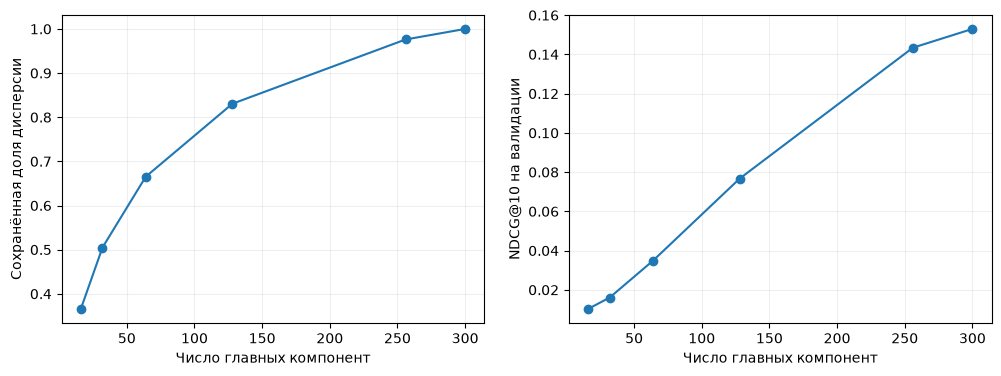

Лучший из проверенных вариантов по валидации: 300 компонент


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(pca_table["Компонент"], pca_table["Доля дисперсии"], marker="o")
axes[0].set(xlabel="Число главных компонент", ylabel="Сохранённая доля дисперсии")
axes[1].plot(pca_table["Компонент"], pca_table["NDCG@10"], marker="o")
axes[1].set(xlabel="Число главных компонент", ylabel="NDCG@10 на валидации")
plt.show()
print(f"Лучший из проверенных вариантов по валидации: {best_pca_dimension} компонент")


Проверим ещё три представления: все исходные координаты без центрирования,
первые 64 исходные координаты и последние 64 главные компоненты.
У последних малая дисперсия, но это само по себе не означает бесполезность.

PCA с 300 компонентами сохраняет всю центрированную матрицу. Сравнение
с исходными 300 координатами показывает также влияние центрирования.


In [ ]:
controls = [
    ("Все исходные координаты", source_vectors, 1.0),
    ("Первые 64 исходные координаты", source_vectors[:, :64],
     np.var(centered_vectors[:, :64], axis=0).sum() / np.var(centered_vectors, axis=0).sum()),
    ("Последние 64 компоненты PCA", pca_coordinates[:, -64:], variance_share[-64:].sum()),
]
control_rows = []
for name, vectors, share in controls:
    values, _ = evaluate_content_vectors(vectors)
    row = metric_row(name, values)
    row.update({"Компонент": vectors.shape[1], "Доля дисперсии": share})
    control_rows.append(row)

first_64 = pca_table.loc[pca_table["Компонент"] == 64]
pd.concat([first_64, pd.DataFrame(control_rows)], ignore_index=True)


,Модель,NDCG@10,Recall@10,"Пользователей с попаданием, %",Пользователей,Компонент,Доля дисперсии
0,PCA: 64,0.034885,0.028640,21.961213,3661,64,0.665339
1,Все исходные координаты,0.150652,0.114879,62.742420,3661,300,1.000000
2,Первые 64 исходные координаты,0.054382,0.043764,30.046435,3661,64,0.211091
3,Последние 64 компоненты PCA,0.031994,0.027789,18.164436,3661,64,0.038312


- Большая сохранённая дисперсия не заменяет проверку рекомендаций.
  PCA оптимизирует восстановление векторов, а не NDCG.
- Исходные координаты и главные компоненты — разные оси. Взять первые
  координаты готового эмбеддинга не равнозначно PCA-сжатию.
- Низкодисперсионные направления могут содержать полезный сигнал.
  Решение об их удалении проверяем по валидации, затем на следующем периоде.


### Длина пользовательской истории

Оставим первые 1, 3, 10 товаров или всю обучающую историю. Порядок — по времени
первого действия. Товарные векторы сохраняются, пользовательские пересчитываются.

Во всех строках одна группа: пользователи минимум с 10 обучающими товарами
и с будущими заказами. Проверяем на всём каталоге.


,Модель,NDCG@10,Recall@10,"Пользователей с попаданием, %",Пользователей
0,Первые 1,0.039398,0.020473,16.778133,3439
1,Первые 3,0.086579,0.053483,36.115150,3439
2,Первые 10,0.117702,0.085442,52.137249,3439
3,Вся история,0.070312,0.056768,36.987496,3439


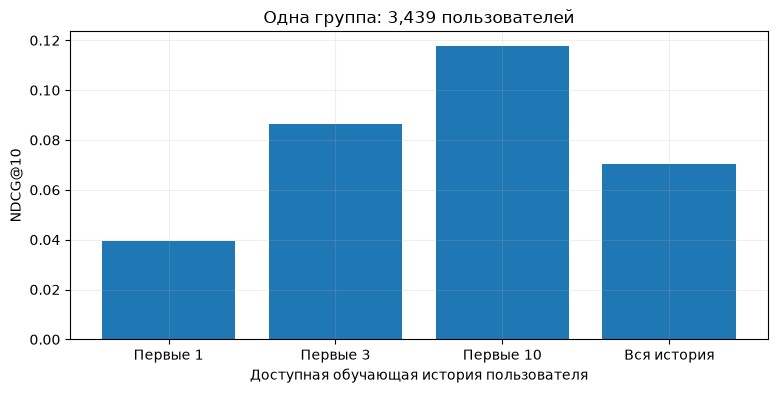

In [ ]:
history_users = valid_users[history_lengths[valid_users] >= 10]
# В архиве пары уже упорядочены по пользователю и времени первого события.
time_history = sparse.csr_matrix(
    (np.ones(len(data["train_u"]), dtype=np.float32), data["train_i"], train.indptr),
    shape=train.shape)

def first_history(matrix, limit):
    rows, cols = [], []
    for u in range(matrix.shape[0]):
        ids = matrix.indices[matrix.indptr[u]:matrix.indptr[u + 1]][:limit]
        rows.extend([u] * len(ids))
        cols.extend(ids)
    return sparse.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=matrix.shape)

history_rows = []
for limit in [1, 3, 10, None]:
    observed = train if limit is None else first_history(time_history, limit)
    X = content.recalculate_user(history_users, observed[history_users] * CONFIDENCE)
    # X содержит только эту группу; сопоставляем глобальные ID локальным строкам.
    local_targets = valid[history_users]
    values = ranking_metrics(factor_scores(X, E), local_targets, np.arange(len(history_users)))
    history_rows.append(metric_row("Вся история" if limit is None else f"Первые {limit}", values))

history_table = pd.DataFrame(history_rows)
display(history_table)
fig, ax = plt.subplots()
ax.bar(history_table["Модель"], history_table["NDCG@10"])
ax.set(xlabel="Доступная обучающая история пользователя", ylabel="NDCG@10",
       title=f"Одна группа: {len(history_users):,} пользователей")
plt.show()


На этой выборке первые три товара дают более высокий NDCG, чем вся история.
Фиксированный вектор пользователя должен объяснить разные группы товаров;
меньшая ошибка по всей истории не гарантирует лучшие первые позиции на будущем.


### Товар без обучающих взаимодействий

Выберем 20% товаров и удалим все их обучающие события. Обе модели заново
обучим на одинаковой истории. Будущие заказы при выборе товаров не используем.

Content ALS сохраняет готовый вектор товара. У iALS без взаимодействий
оптимальный товарный вектор нулевой: зададим нули явно после обучения.

Проверим скрытые цели сначала среди скрытых товаров, затем среди всего
каталога. Во втором случае остальные товары тоже участвуют в ранжировании,
но измеряем только обнаружение целей из выбранной группы.


In [ ]:
hidden_rng = np.random.default_rng(SEED)
hidden_items = np.sort(hidden_rng.choice(N_ITEMS, size=N_ITEMS // 5, replace=False))
hidden_mask = np.zeros(N_ITEMS, dtype=bool)
hidden_mask[hidden_items] = True
limited_train = train.copy()
limited_train.data[hidden_mask[limited_train.indices]] = 0
limited_train.eliminate_zeros()
hidden_content = fixed_content_model(E, N_USERS)
hidden_content.partial_fit_users(np.arange(N_USERS), limited_train * CONFIDENCE)
hidden_ials = AlternatingLeastSquares(factors=FACTORS, iterations=ALS_EPOCHS, regularization=REGULARIZATION,
                                     alpha=1, num_threads=4, random_state=SEED)
hidden_ials.fit(limited_train * CONFIDENCE, show_progress=False)
hidden_ials.item_factors[hidden_items] = 0

hidden_targets = valid.multiply(hidden_mask).tocsr()
hidden_targets.eliminate_zeros()
hidden_users = np.flatnonzero(np.diff(hidden_targets.indptr))
hidden_values, hidden_rows = {}, []
for name, model in [("Content ALS", hidden_content), ("iALS", hidden_ials)]:
    # Нулевые iALS-векторы задают ничью; отдельный случайный ориентир идёт ниже.
    item_vectors = model.item_factors[hidden_items]
    values = ranking_metrics(factor_scores(model.user_factors, item_vectors),
                             hidden_targets[:, hidden_items], hidden_users)
    hidden_values[name] = values
    hidden_rows.append(metric_row(name + ": только скрытые товары", values))
    mixed = ranking_metrics(factor_scores(model.user_factors, model.item_factors),
                            hidden_targets, hidden_users)
    hidden_rows.append(metric_row(name + ": скрытые цели в полном каталоге", mixed))

# Ожидание NDCG случайного порядка не зависит от соглашения о разрешении ничьих.
counts = np.asarray(hidden_targets[hidden_users].sum(axis=1)).ravel()
discount = 1 / np.log2(np.arange(2, K + 2))
ideal = np.cumsum(discount)[np.minimum(counts.astype(int), K) - 1]
random_ndcg = (counts / len(hidden_items) * discount.sum() / ideal).mean()
display(pd.DataFrame(hidden_rows))
print(f"Ожидаемый NDCG@10 случайного порядка среди скрытых товаров: {random_ndcg:.5f}")
print(f"Пользователей со скрытыми целями: {len(hidden_users):,}; товаров: {len(hidden_items):,}")


,Модель,NDCG@10,Recall@10,"Пользователей с попаданием, %",Пользователей
0,Content ALS: только скрытые товары,0.032611,0.047050,10.938053,2825
1,Content ALS: скрытые цели в полном каталоге,0.008185,0.013267,3.256637,2825
2,iALS: только скрытые товары,0.002207,0.004039,0.849558,2825
3,iALS: скрытые цели в полном каталоге,0.000000,0.000000,0.000000,2825


Ожидаемый NDCG@10 случайного порядка среди скрытых товаров: 0.00295
Пользователей со скрытыми целями: 2,825; товаров: 2,000


Перемешаем векторы между товарами и заново обучим пользователей.
Размерность и набор векторов сохранятся; связь товара с его признаками исчезнет.
Сравним на тех же скрытых целях.


In [ ]:
shuffled_E = E[np.random.default_rng(SEED + 1).permutation(N_ITEMS)].copy()
shuffled = fixed_content_model(shuffled_E, N_USERS)
shuffled.partial_fit_users(np.arange(N_USERS), limited_train * CONFIDENCE)
shuffled_values = ranking_metrics(factor_scores(shuffled.user_factors, shuffled_E[hidden_items]),
                                 hidden_targets[:, hidden_items], hidden_users)
pd.DataFrame([metric_row("Исходное соответствие товар → вектор", hidden_values["Content ALS"]),
              metric_row("Векторы перемешаны между товарами", shuffled_values)])


,Модель,NDCG@10,Recall@10,"Пользователей с попаданием, %",Пользователей
0,Исходное соответствие товар → вектор,0.032611,0.047050,10.938053,2825
1,Векторы перемешаны между товарами,0.002460,0.004786,1.238938,2825


### Новое событие пользователя

Добавим товары в историю выбранного пользователя и пересчитаем его вектор.
В `partial_fit_users` передаём **всю накопленную историю**, а не только новое
событие. Проверим, что другой пользователь и товарные факторы не изменились.


In [ ]:
ordered_history = data["train_i"][data["train_u"] == demo_user]
update_model = fixed_content_model(E, N_USERS)
untouched_user = (demo_user + 1) % N_USERS
untouched_before = update_model.user_factors[untouched_user].copy()
updates = []
for length in [1, 3, 10, len(ordered_history)]:
    ids = ordered_history[:length]
    row = sparse.csr_matrix((np.full(len(ids), CONFIDENCE, dtype=np.float32),
                             (np.zeros(len(ids), dtype=int), ids)), shape=(1, N_ITEMS))
    update_model.partial_fit_users([demo_user], row)
    top = np.argsort(-(E @ update_model.user_factors[demo_user]), kind="stable")[:5]
    updates.append({"Товаров в истории": len(ids),
                    "Первые 5 рекомендаций": ", ".join(catalog.iloc[top]["Товар"]),
                    "Подкатегории": "; ".join(catalog.iloc[top]["Подкатегория"])})
assert np.array_equal(untouched_before, update_model.user_factors[untouched_user])
assert np.array_equal(E, update_model.item_factors)
pd.DataFrame(updates)


,Товаров в истории,Первые 5 рекомендаций,Подкатегории
0,1,"fmcg_657136, fmcg_104242, fmcg_944103, fmcg_24...",Sweet Desserts and Confectionery; Sweet Desser...
1,3,"fmcg_66926, fmcg_393412, fmcg_269399, fmcg_111...",Storage and Transport Containers; Storage and ...
2,10,"fmcg_146229, fmcg_465495, fmcg_800358, fmcg_90...","Fresh Vegetables, Fruits, and Greens; Fresh Ve..."
3,31,"fmcg_133028, fmcg_334073, fmcg_536167, fmcg_73...","Fresh Vegetables, Fruits, and Greens; Fresh Ve..."


## Проверка на следующем периоде

Добавляем в историю события до 1282.5 и заново обучаем модели с выбранными
настройками. Тест начинается в день 1283; сохраняется разрыв 12 часов.
Каталог и товарные признаки остаются прежними.


In [ ]:
refit = interactions("refit")
refit_u, refit_i = refit.nonzero()
refit_keys = np.sort(refit_u.astype(np.int64) * N_ITEMS + refit_i)
final_mf_values = {}
for loss in ["MSE", "BPR"]:
    X, Y = initial_X.copy(), initial_Y.copy()
    order_rng = np.random.default_rng(SEED)
    negative_rng = np.random.default_rng(SEED + 2)
    for epoch in range(selected_epochs[loss]):
        negative = draw_negatives(refit_u, negative_rng, refit_keys)
        mf_epoch(X, Y, refit_u, refit_i, negative,
                 order_rng.permutation(len(refit_u)), loss)
    final_mf_values[loss] = ranking_metrics(factor_scores(X, Y), test, test_users)

final_content = fixed_content_model(E, N_USERS)
final_content.partial_fit_users(np.arange(N_USERS), refit * CONFIDENCE)
final_ials = AlternatingLeastSquares(factors=FACTORS, iterations=ALS_EPOCHS, regularization=REGULARIZATION,
                                     alpha=1, num_threads=4, random_state=SEED)
final_ials.fit(refit * CONFIDENCE, show_progress=False)
final_popularity = np.asarray(refit.sum(axis=0)).ravel()
final_content_values = ranking_metrics(factor_scores(final_content.user_factors, E), test, test_users)
final_ials_values = ranking_metrics(factor_scores(final_ials.user_factors, final_ials.item_factors), test, test_users)
final_pop_values = ranking_metrics(lambda users: np.broadcast_to(final_popularity, (len(users), N_ITEMS)),
                                   test, test_users)
final_pca_model = fixed_content_model(best_pca_vectors, N_USERS)
final_pca_model.partial_fit_users(np.arange(N_USERS), refit * CONFIDENCE)
final_pca_values = ranking_metrics(factor_scores(final_pca_model.user_factors, best_pca_vectors),
                                   test, test_users)
pd.DataFrame([metric_row("Популярность", final_pop_values)] +
             [metric_row(name, values) for name, values in final_mf_values.items()] +
             [metric_row("Content ALS, 128", final_content_values),
              metric_row(f"Content ALS, PCA {best_pca_dimension}", final_pca_values),
              metric_row("iALS", final_ials_values)])


,Модель,NDCG@10,Recall@10,"Пользователей с попаданием, %",Пользователей
0,Популярность,0.197201,0.111315,74.823466,3682
1,MSE,0.157981,0.113222,71.537208,3682
2,BPR,0.230345,0.127500,74.769147,3682
3,"Content ALS, 128",0.070855,0.056446,38.185769,3682
4,"Content ALS, PCA 300",0.143998,0.108499,60.021727,3682
5,iALS,0.246909,0.168318,79.250407,3682


## Выводы

- MSE штрафует ошибки значений, BPR — неправильный порядок пар.
  Снижение обучающей потери не гарантирует рост NDCG.
- На тесте NDCG@10: MSE — 0,158, BPR — 0,230, популярность — 0,197.
  Эпоха остановки каждой MF выбрана по валидации.
- Случайные кандидаты облегчают проверку. Их метрика не заменяет оценку
  полного каталога.
- При фиксированных товарах обучение пользователя — квадратичная задача.
  Градиентные шаги приближаются к решению; точный пересчёт не зависит от инициализации.
- В `implicit` товары сохраняют `partial_fit_users` и `recalculate_user`.
  Для обновления пользователя нужна вся текущая история.
- Долю дисперсии PCA нельзя использовать вместо качества рекомендаций.
  Размерность выбираем по валидации и отдельно проверяем на будущем.
- При скрытой истории исходные векторы полезнее перемешанных.
  Полный каталог и товары со скрытой историей оцениваются отдельно.


## Extra: PageRank и Personalized PageRank

Построим граф товаров, которые встречались у одних пользователей.
Сначала разберём обход пяти вершин, затем применим тот же код к T-ECD.


### Случайное блуждание

$P_{ij}$ — вероятность перехода из $i$ в $j$.
С вероятностью $\alpha$ идём по ребру, с вероятностью $1-\alpha$ возвращаемся
в вершину из распределения $v$. Если исходящих рёбер нет, тоже выбираем по $v$.

$$r^{(t+1)}=\alpha P^\top r^{(t)}+
\left(1-\alpha+\alpha\sum_{i:\,\deg^+(i)=0}r_i^{(t)}\right)v.$$

В PageRank $v$ равномерно. В Personalized PageRank возвраты идут в историю
пользователя. При $\alpha<1$ процесс сходится; $r_i$ — масса обхода, не вероятность заказа.


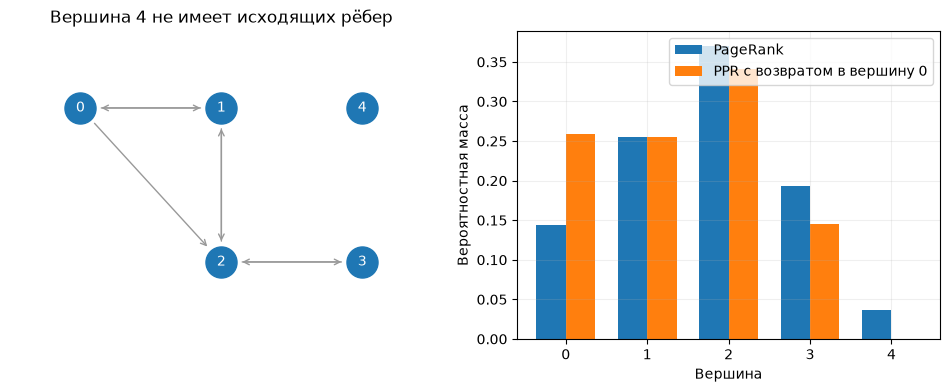

In [ ]:
def transition_matrix(adjacency):
    weight = np.asarray(adjacency.sum(axis=1)).ravel()
    inverse = np.divide(1, weight, out=np.zeros_like(weight, dtype=np.float64), where=weight > 0)
    return (sparse.diags(inverse) @ adjacency).tocsr(), weight == 0

def pagerank(P, dangling, restart, alpha=0.85, tolerance=1e-8, max_steps=150):
    v = np.asarray(restart, dtype=np.float64)
    v = v / v.sum()
    rank = v.copy()
    residuals = []
    for _ in range(max_steps):
        new = alpha * (P.T @ rank) + (1 - alpha + alpha * rank[dangling].sum()) * v
        residuals.append(np.abs(new - rank).sum())
        rank = new
        if residuals[-1] < tolerance:
            break
    return rank, residuals

toy_adjacency = sparse.csr_matrix(np.array([
    [0, 1, 1, 0, 0], [1, 0, 1, 0, 0], [0, 1, 0, 1, 0],
    [0, 0, 1, 0, 0], [0, 0, 0, 0, 0]], dtype=float))
toy_P, toy_dangling = transition_matrix(toy_adjacency)
toy_pr, toy_residuals = pagerank(toy_P, toy_dangling, np.ones(5))
toy_ppr, _ = pagerank(toy_P, toy_dangling, np.array([1, 0, 0, 0, 0]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
positions = np.array([[0, 1], [1, 1], [1, 0], [2, 0], [2, 1]])
for i, j in zip(*toy_adjacency.nonzero()):
    axes[0].annotate("", xy=positions[j], xytext=positions[i],
                     arrowprops={"arrowstyle": "->", "color": "0.6", "shrinkA": 15, "shrinkB": 15})
axes[0].scatter(*positions.T, s=500, zorder=3)
for i, pos in enumerate(positions):
    axes[0].text(*pos, str(i), ha="center", va="center", color="white", zorder=4)
axes[0].set(xlim=(-0.5, 2.5), ylim=(-0.5, 1.5), title="Вершина 4 не имеет исходящих рёбер")
axes[0].axis("off")
axis = np.arange(5)
axes[1].bar(axis - 0.18, toy_pr, width=0.36, label="PageRank")
axes[1].bar(axis + 0.18, toy_ppr, width=0.36, label="PPR с возвратом в вершину 0")
axes[1].set(xlabel="Вершина", ylabel="Вероятностная масса", xticks=axis)
axes[1].legend()
plt.show()
assert np.isclose(toy_pr.sum(), 1) and np.isclose(toy_ppr.sum(), 1)


### Граф товаров

Берём до 20 последних товаров пользователя. Вес ребра — число общих пользователей.
Оставляем связи минимум с двумя совпадениями и до 20 соседей каждой вершины.
Граф отражает совместный интерес, а не порядок покупок; после отбора соседей
он может стать направленным.


In [ ]:
def recent_history(matrix, limit=20):
    rows, cols = [], []
    for u in range(matrix.shape[0]):
        ids = matrix.indices[matrix.indptr[u]:matrix.indptr[u + 1]][-limit:]
        rows.extend([u] * len(ids))
        cols.extend(ids)
    return sparse.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=matrix.shape)

graph_history = recent_history(time_history)
cooccurrence = (graph_history.T @ graph_history).tocsr()
cooccurrence.setdiag(0)
cooccurrence.data[cooccurrence.data < 2] = 0
cooccurrence.eliminate_zeros()

# Оставляем 20 наиболее сильных исходящих связей; равенства разрешаем по ID.
for i in range(N_ITEMS):
    start, end = cooccurrence.indptr[i:i + 2]
    order = np.lexsort((cooccurrence.indices[start:end], -cooccurrence.data[start:end]))
    cooccurrence.data[start:end][order[20:]] = 0
cooccurrence.eliminate_zeros()
P, dangling = transition_matrix(cooccurrence)
print(f"Вершин: {N_ITEMS:,}; рёбер: {P.nnz:,}; без исходящих связей: {dangling.sum():,}")


Вершин: 10,000; рёбер: 123,245; без исходящих связей: 73


### Общий список рекомендаций

Популярность считает пользователей товара. PageRank учитывает переходы
от соседей. Сравним списки и качество на будущих заказах.


In [ ]:
global_rank, residuals = pagerank(P, dangling, np.ones(N_ITEMS))
global_values = ranking_metrics(lambda users: np.broadcast_to(global_rank, (len(users), N_ITEMS)),
                                valid, valid_users)
display(pd.DataFrame([metric_row("Популярность", pop_values), metric_row("PageRank", global_values)]))
top_lists = []
for name, score in [("Популярность", popularity), ("PageRank", global_rank)]:
    ids = np.argsort(-score, kind="stable")[:8]
    frame = catalog.iloc[ids].copy()
    frame.insert(0, "Метод", name)
    frame["Позиция"] = np.arange(1, len(ids) + 1)
    top_lists.append(frame)
pd.concat(top_lists, ignore_index=True)


,Модель,NDCG@10,Recall@10,"Пользователей с попаданием, %",Пользователей
0,Популярность,0.187749,0.111333,70.527178,3661
1,PageRank,0.187892,0.112130,67.768369,3661


,Метод,Товар,Категория,Подкатегория,Позиция
0,Популярность,fmcg_180861,Home Improvement and Countryside Retreat Essen...,Storage and Transport Containers,1
1,Популярность,fmcg_66926,Home Improvement and Countryside Retreat Essen...,Storage and Transport Containers,2
2,Популярность,fmcg_651828,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens",3
3,Популярность,fmcg_514296,Foodstuffs and Beverages,Dairy Products and Eggs,4
4,Популярность,fmcg_335947,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens",5
5,Популярность,fmcg_592380,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens",6
6,Популярность,fmcg_250877,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens",7
7,Популярность,fmcg_450490,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens",8
8,PageRank,fmcg_180861,Home Improvement and Countryside Retreat Essen...,Storage and Transport Containers,1
9,PageRank,fmcg_66926,Home Improvement and Countryside Retreat Essen...,Storage and Transport Containers,2


### Персонализация

Возвращаем обход в последние товары пользователя. Граф остаётся прежним,
меняется только $v$. Посмотрим списки двух пользователей с разными интересами,
затем проверим PPR на общей группе. Повторные покупки по-прежнему допустимы.


In [ ]:
example_users, used_categories = [], set()
for u in np.argsort(-history_lengths, kind="stable"):
    ids = time_history.indices[time_history.indptr[u]:time_history.indptr[u + 1]][-20:]
    labels, counts = np.unique(data["subcategory"][ids], return_counts=True)
    category = labels[np.argmax(counts)]
    if category != "Unknown" and category not in used_categories:
        example_users.append(int(u))
        used_categories.add(category)
    if len(example_users) == 2:
        break

example_rows = []
for u in example_users:
    restart = graph_history[u].toarray().ravel()
    personal_rank, _ = pagerank(P, dangling, restart)
    ids = np.argsort(-personal_rank, kind="stable")[:8]
    frame = catalog.iloc[ids].copy()
    frame.insert(0, "Пользователь", u)
    example_rows.append(frame)
display(pd.concat(example_rows, ignore_index=True))


,Пользователь,Товар,Категория,Подкатегория
0,1658,fmcg_180861,Home Improvement and Countryside Retreat Essen...,Storage and Transport Containers
1,1658,fmcg_66926,Home Improvement and Countryside Retreat Essen...,Storage and Transport Containers
2,1658,fmcg_335947,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens"
3,1658,fmcg_235269,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens"
4,1658,fmcg_777801,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens"
5,1658,fmcg_188370,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens"
6,1658,fmcg_243275,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens"
7,1658,fmcg_651828,Foodstuffs and Beverages,"Fresh Vegetables, Fruits, and Greens"
8,12576,fmcg_180861,Home Improvement and Countryside Retreat Essen...,Storage and Transport Containers
9,12576,fmcg_66926,Home Improvement and Countryside Retreat Essen...,Storage and Transport Containers


Для проверки всех пользователей считаем обход пакетами: каждая колонка имеет
своё распределение возвратов, матрица переходов общая.


In [ ]:
def personal_scores(users, alpha=0.85, max_steps=100, tolerance=1e-6):
    v = graph_history[users].T.toarray().astype(np.float64)
    v /= v.sum(axis=0, keepdims=True)
    rank = v.copy()
    for _ in range(max_steps):
        mass = rank[dangling].sum(axis=0)
        new = alpha * (P.T @ rank) + v * (1 - alpha + alpha * mass)
        error = np.max(np.abs(new - rank).sum(axis=0))
        rank = new
        if error < tolerance:
            break
    return rank.T

started = perf_counter()
personal_values = ranking_metrics(personal_scores, valid, valid_users)
display(pd.DataFrame([metric_row("Популярность", pop_values),
                      metric_row("PageRank", global_values),
                      metric_row("Personalized PageRank", personal_values)]))
print(f"Проверка Personalized PageRank: {perf_counter() - started:.1f} с")


,Модель,NDCG@10,Recall@10,"Пользователей с попаданием, %",Пользователей
0,Популярность,0.187749,0.111333,70.527178,3661
1,PageRank,0.187892,0.112130,67.768369,3661
2,Personalized PageRank,0.232001,0.137585,77.082764,3661


Проверка Personalized PageRank: 14.0 с


## Выводы по графовой части

- PageRank зависит от связей графа, а не только от числа действий с товаром.
- Personalized PageRank использует тот же граф и возвращает обход в историю
  конкретного пользователя. На валидации NDCG@10: общий PageRank — 0,188,
  персонализированный — 0,232. Общий список здесь близок к популярности.
- Масса обхода не равна вероятности заказа. Качество рекомендаций проверяем
  по будущим действиям пользователей.
